# Multivariate Nested Kriging Playground: `ett2/H`

**Dataset:** `ett2/H` | **target_dim (p):** 7 |
**prediction length (short):** 48

**Architecture:** Two-layer nested kriging with a *shared* Gibbs
lengthscale field across all 7 output channels.

- **Layer 1** (`fit_gibbs_lengthscale_field`): fitted on pooled cross-channel
  windows → shared ℓ̃(x) field.
- **Layer 2** (`MultivariateNestedKrigingForecaster`): one
  `NestedKrigingForecaster` per output channel, each using the shared ℓ̃
  field via the Rullière et al. aggregation.

Edit the parameter cell freely. Cells are separated so you can re-run
only the parts you want.

In [1]:
import os
import sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError(
        "Could not locate the KMD_TS repository root from the current working directory."
    )

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)
print("GIFT_EVAL:", os.environ["GIFT_EVAL"])

Repo root: /Users/jonghyeonlee/KMD_TS
GIFT_EVAL: /Users/jonghyeonlee/KMD_TS/GiftEval_data


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from gift_eval.data import Dataset
from src.nested_kriging import (
    LengthscaleField,
    MultivariateNestedKrigingForecaster,
    fit_gibbs_lengthscale_field,
    pool_windows_from_multivariate_series as pool_windows_mv,
)

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


In [3]:
DATASET_NAME = "ett2/H"
TERM = "short"
TO_UNIVARIATE = False       # must be False for multivariate datasets

# ── Dataset properties (read-only — change TERM if you want medium/long) ──
TARGET_DIM = 7               # p: number of output channels

# ── Series to preview ──────────────────────────────────────────────────
SERIES_INDEX = 0
CHANNEL_INDEX = 0           # which channel to plot in preview / uncertainty cells

# ── Window bank controls ───────────────────────────────────────────────
MAX_SERIES = 1
MAX_WINDOWS_PER_SERIES = 200

CONTEXT_LENGTH = 168       # L: per-channel context window length
HORIZON_LENGTH = None       # H: defaults to dataset.prediction_length

NORMALIZATION = "robust_series"  # per-channel robust normalisation  # No-missing pooler (switch to with_missing variant if NaNs detected)
MIN_OBS_FRACTION = 0.5      # only used by the with_missing pooler

# ── Layer 1 — lengthscale field (shared across all channels) ───────────
BLOCK_SIZE_L1 = 10      # windows per block for local ℓ̂_m MLE
SIGMA_N_L1 = 0.1
AMPLITUDE_L1 = 1.0
LOG_ELL_LO = 0.0
LOG_ELL_HI = 4.03
META_AMPLITUDE = 1.0
META_BANDWIDTH = None       # None → median-heuristic bandwidth

# ── Layer 2 — MultivariateNestedKrigingForecaster ─────────────────────
BLOCK_SIZE_L2 = 30          # target block size per channel
MAX_BLOCKS_L2 = 30          # cap on M per channel
SIGMA_N_L2 = 0.1
AMPLITUDE_L2 = 1.0

# ── Evaluation ─────────────────────────────────────────────────────────
EVALUATE_ALL_SERIES = False
EVAL_SERIES_LIMIT = None

In [4]:
dataset = Dataset(
    name=DATASET_NAME,
    term=TERM,
    to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)

print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)
assert dataset.target_dim == TARGET_DIM, (
    f"Expected target_dim={TARGET_DIM} but got {dataset.target_dim}"
)

dataset_name       : ett2/H
frequency          : H
prediction_length  : 48
test windows/series: 20
n_raw_series       : 1
target_dim         : 7


/Users/jonghyeonlee/KMD_TS/gift_eval/data.py:151: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  freq = norm_freq_str(to_offset(self.freq).name)


In [5]:
# ── Data access helpers (multivariate-aware) ──────────────────────────

def _nth_item(data_it, index: int):
    for i, item in enumerate(data_it):
        if i == index:
            return item
    raise IndexError(f"Index {index} is out of range.")


def _series_from_entry_mv(entry) -> np.ndarray:
    """Return (T, p) array from a GluonTS DataEntry.

    gift_eval stores multivariate targets as (p, T) — transpose to (T, p).
    """
    tgt = np.asarray(entry["target"], dtype=float)
    if tgt.ndim == 1:
        return tgt[:, None]   # (T, 1) for safety
    return tgt.T              # (p, T) → (T, p)


def _get_train_entry(series_index: int):
    return _nth_item(dataset.training_dataset, series_index)


def _get_validation_entry(series_index: int):
    return _nth_item(dataset.validation_dataset, series_index)


def _get_test_pair(series_index: int, window_index: int):
    if window_index < 0 or window_index >= dataset.windows:
        raise IndexError(
            f"window_index={window_index} out of range "
            f"(dataset.windows={dataset.windows})"
        )
    flat_index = series_index * dataset.windows + window_index
    test_ctx  = _nth_item(dataset.test_data.input, flat_index)
    test_lbl  = _nth_item(dataset.test_data.label, flat_index)
    return test_ctx, test_lbl


def _collect_train_series_mv(*, max_series: int | None) -> list[np.ndarray]:
    """Return list of (T, p) arrays from the training split."""
    out = []
    for i, entry in enumerate(dataset.training_dataset):
        if max_series is not None and i >= max_series:
            break
        arr = _series_from_entry_mv(entry)
        if arr.size > 0:
            out.append(arr)
    return out


def _collect_val_series_mv(*, max_series: int | None) -> list[np.ndarray]:
    out = []
    for i, entry in enumerate(dataset.validation_dataset):
        if max_series is not None and i >= max_series:
            break
        arr = _series_from_entry_mv(entry)
        if arr.size > 0:
            out.append(arr)
    return out


def _denorm(pred_norm: np.ndarray, loc: float, scale: float) -> np.ndarray:
    return pred_norm * scale + loc


def relative_l2_error(true: np.ndarray, pred: np.ndarray) -> float:
    t = np.asarray(true, dtype=float).ravel()
    p = np.asarray(pred, dtype=float).ravel()
    denom = float(np.sum(t ** 2))
    if denom < 1e-12:
        # Target is near-zero — fall back to absolute L2 so the metric stays finite.
        return float(np.sum((t - p) ** 2))
    return float(np.sum((t - p) ** 2) / denom)


def _plot_channel_forecast(y_true, y_pred, *, channel: int, title: str):
    t = np.arange(1, len(y_true) + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(t, y_true, label="true", linewidth=2)
    plt.plot(t, y_pred, label="predicted", linewidth=2)
    plt.title(f"{title}  [channel {channel}]")
    plt.xlabel("horizon step")
    plt.ylabel("value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def _evaluation_series_indices(n_available: int) -> list[int]:
    if not EVALUATE_ALL_SERIES:
        return [SERIES_INDEX]
    limit = n_available if EVAL_SERIES_LIMIT is None else min(int(EVAL_SERIES_LIMIT), n_available)
    return list(range(max(1, limit)))

Series 0: train shape = (16412, 7), val shape = (16460, 7)
Target channels (p) = 7


/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return pd.Period(val, freq)


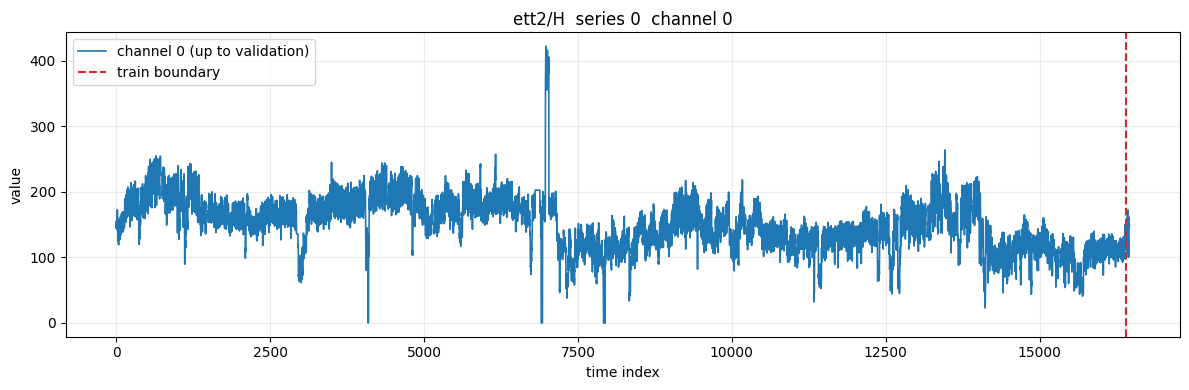

In [6]:
# ── Preview: selected series, selected channel ────────────────────────
train_entry = _get_train_entry(SERIES_INDEX)
val_entry   = _get_validation_entry(SERIES_INDEX)
train_mv    = _series_from_entry_mv(train_entry)   # (T_train, p)
val_mv      = _series_from_entry_mv(val_entry)     # (T_val, p)
p_actual    = train_mv.shape[1]

print(f"Series {SERIES_INDEX}: train shape = {train_mv.shape}, val shape = {val_mv.shape}")
print(f"Target channels (p) = {p_actual}")

val_extra = val_mv[train_mv.shape[0]:]            # (val_train len, p)

ch = min(CHANNEL_INDEX, p_actual - 1)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(np.arange(val_mv.shape[0]), val_mv[:, ch],
        linewidth=1.2, label=f"channel {ch} (up to validation)")
ax.axvline(train_mv.shape[0], color="tab:red", linestyle="--", label="train boundary")
ax.set_title(f"{DATASET_NAME}  series {SERIES_INDEX}  channel {ch}")
ax.set_xlabel("time index")
ax.set_ylabel("value")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Layer 1 — Fit Shared Lengthscale Field (training split)

In [7]:
rng = np.random.default_rng(42)
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

# ── Collect training series ─────────────────────────────────────────
print("Collecting training series …")
train_series_list = _collect_train_series_mv(max_series=MAX_SERIES)
print(f"  {len(train_series_list)} series, shape[0] example: "
      f"{train_series_list[0].shape if train_series_list else 'N/A'}")

# ── Pool windows cross-channel (all channels pooled together) ───────
print("Pooling cross-channel windows …")
pool_kwargs = dict(
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    rng=rng,
)
ctx_train, tgt_train, meta_train, n_channels = pool_windows_mv(
    train_series_list, **pool_kwargs
)
print(f"  pooled {ctx_train.shape[0]} windows across {n_channels} channels")
print(f"  context shape: {ctx_train.shape}, target shape: {tgt_train.shape}")

# Per-channel window counts
ch_idx = [m["channel_idx"] for m in meta_train]
for ch in range(n_channels):
    cnt = sum(c == ch for c in ch_idx)
    print(f"    channel {ch}: {cnt} windows")

# ── Layer 1: fit shared lengthscale field ───────────────────────────
print("\nFitting Layer 1 (shared Gibbs lengthscale field) …")
ell_field = fit_gibbs_lengthscale_field(
    ctx_train, tgt_train,
    block_size_l1=BLOCK_SIZE_L1,
    sigma_n=SIGMA_N_L1,
    amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE,
    meta_bandwidth=META_BANDWIDTH,
    rng=rng,
)
print(f"  anchors (M_1)  : {ell_field.n_anchors}")
print(f"  meta_bandwidth : {ell_field.meta_bandwidth:.4f}")
sample_ell = ell_field.predict_ell(ctx_train[:5])
print(f"  sample ℓ̃ values: {sample_ell}")

  1 series, shape[0] example: (16412, 7)
Pooling cross-channel windows …
  pooled 1400 windows across 7 channels
  context shape: (1400, 168), target shape: (1400, 48)
    channel 0: 200 windows
    channel 1: 200 windows
    channel 2: 200 windows
    channel 3: 200 windows
    channel 4: 200 windows
    channel 5: 200 windows
    channel 6: 200 windows

Fitting Layer 1 (shared Gibbs lengthscale field) …
  anchors (M_1)  : 140
  meta_bandwidth : 4.1315
  sample ℓ̃ values: [8.17521274 2.95504594 2.03988367 1.7227573  1.6507752 ]


## Layer 2 — Fit MultivariateNestedKrigingForecaster (training split)

In [8]:
# ── Layer 2: fit MultivariateNestedKrigingForecaster ────────────────
print("Fitting Layer 2 (MultivariateNestedKrigingForecaster) …")
mv_forecaster = MultivariateNestedKrigingForecaster(
    ell_field,
    n_channels=n_channels,
    block_size=BLOCK_SIZE_L2,
    max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2,
    amplitude=AMPLITUDE_L2,
    rng=rng,
).fit(ctx_train, tgt_train, meta_train)

for ch, fc in enumerate(mv_forecaster._forecasters):
    if fc._fitted_blocks:
        n_blk = len(fc._fitted_blocks)
        sizes = [len(b.indices) for b in fc._fitted_blocks]
        print(f"  channel {ch}: {n_blk} blocks, "
              f"sizes min={min(sizes)} max={max(sizes)} mean={np.mean(sizes):.1f}")
    else:
        print(f"  channel {ch}: no blocks fitted (insufficient windows)")

Fitting Layer 2 (MultivariateNestedKrigingForecaster) …
  channel 0: 7 blocks, sizes min=20 max=30 mean=28.6
  channel 1: 7 blocks, sizes min=20 max=30 mean=28.6
  channel 2: 7 blocks, sizes min=20 max=30 mean=28.6
  channel 3: 7 blocks, sizes min=20 max=30 mean=28.6
  channel 4: 7 blocks, sizes min=20 max=30 mean=28.6
  channel 5: 7 blocks, sizes min=20 max=30 mean=28.6
  channel 6: 7 blocks, sizes min=20 max=30 mean=28.6


## Short-Term Evaluation: train → validation \ train

Short-term evaluation (train → validation\train) …


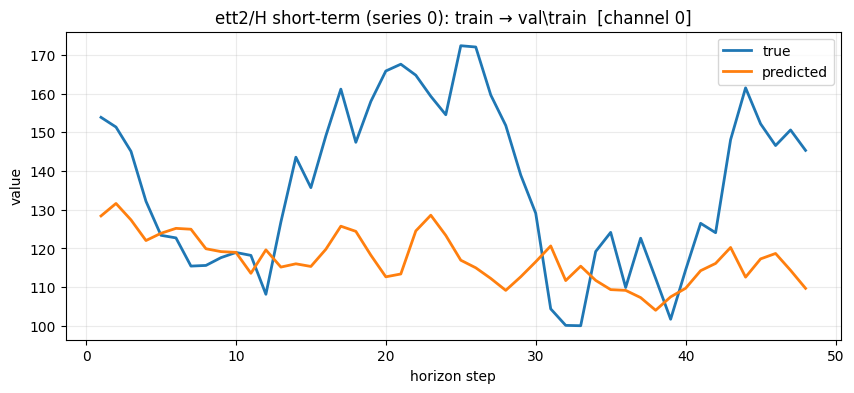

Short-term evaluated : 7 (series × channel) pairs
Mean  relative L2    : 52.860688
Median relative L2   : 0.053497


In [9]:
# ── Short-term evaluation: train → validation\train ──────────────────
print("Short-term evaluation (train → validation\\train) …")
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_series_total = len(dataset.hf_dataset)

all_errors = []     # (channel, series) relative L2 errors
plotted = False

for eval_idx in _evaluation_series_indices(n_series_total):
    train_arr = _series_from_entry_mv(_get_train_entry(eval_idx))   # (T, p)
    val_arr   = _series_from_entry_mv(_get_validation_entry(eval_idx))
    T_train = train_arr.shape[0]
    val_extra = val_arr[T_train:]                               # (val_extra, p)

    if T_train < CONTEXT_LENGTH or val_extra.shape[0] < horizon_length:
        continue

    p = train_arr.shape[1]
    # Build (p, L) query from last L steps of each training channel
    query = np.stack(
        [train_arr[-CONTEXT_LENGTH:, ch] for ch in range(p)], axis=0
    )   # (p, L)

    # Normalise: per-channel, using training stats
    query_norm = np.empty_like(query)
    locs, scales = [], []
    for ch in range(p):
        ch_arr = train_arr[:, ch]
        if NORMALIZATION == "robust_series":
            loc = float(np.nanmedian(ch_arr))
            q75 = float(np.nanpercentile(ch_arr, 75))
            q25 = float(np.nanpercentile(ch_arr, 25))
            _iqr_s = (q75 - q25) / 1.349
            scale = max(
                _iqr_s if np.isfinite(_iqr_s) else 0.0,
                float(np.nanstd(ch_arr)) if np.isfinite(float(np.nanstd(ch_arr))) else 0.0,
                1e-6,
            )
        else:
            loc, scale = 0.0, 1.0
        query_norm[ch] = (query[ch] - loc) / scale
        locs.append(loc); scales.append(scale)

    pred_norm = mv_forecaster.predict(query_norm)   # (p, H)

    series_errors = []
    for ch in range(p):
        pred_ch = _denorm(pred_norm[ch], locs[ch], scales[ch])
        true_ch = val_extra[:horizon_length, ch]
        err = relative_l2_error(true_ch, pred_ch)
        series_errors.append(err)
        all_errors.append(err)

    if (not EVALUATE_ALL_SERIES and eval_idx == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and not plotted
    ):
        ch_plot = min(CHANNEL_INDEX, p - 1)
        _plot_channel_forecast(
            val_extra[:horizon_length, ch_plot],
            _denorm(pred_norm[ch_plot], locs[ch_plot], scales[ch_plot]),
            channel=ch_plot,
            title=f"{DATASET_NAME} short-term (series {eval_idx}): train → val\\train",
        )
        plotted = True

if all_errors:
    arr = np.asarray(all_errors, dtype=float)
    print(f"Short-term evaluated : {len(all_errors)} (series × channel) pairs")
    print(f"Mean  relative L2    : {float(np.nanmean(arr)):.6f}")
    print(f"Median relative L2   : {float(np.nanmedian(arr)):.6f}")
else:
    print("No short-term forecasts could be evaluated.")

## Re-Fit on Validation Split (for test evaluation)

In [10]:
# ── Re-fit on validation split (for test evaluation) ────────────────
print("Collecting validation series …")
val_series_list = _collect_val_series_mv(max_series=MAX_SERIES)
print(f"  {len(val_series_list)} series")
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

print("Pooling validation windows …")
pool_kwargs_val = dict(
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    rng=rng,
)
ctx_val, tgt_val, meta_val, _ = pool_windows_mv(
    val_series_list, **pool_kwargs_val
)
print(f"  pooled {ctx_val.shape[0]} windows")

print("\nFitting Layer 1 on validation split …")
ell_field_val = fit_gibbs_lengthscale_field(
    ctx_val, tgt_val,
    block_size_l1=BLOCK_SIZE_L1,
    sigma_n=SIGMA_N_L1,
    amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE,
    meta_bandwidth=META_BANDWIDTH,
    rng=rng,
)
print(f"  anchors: {ell_field_val.n_anchors}")

print("Fitting Layer 2 on validation split …")
mv_forecaster_val = MultivariateNestedKrigingForecaster(
    ell_field_val,
    n_channels=n_channels,
    block_size=BLOCK_SIZE_L2,
    max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2,
    amplitude=AMPLITUDE_L2,
    rng=rng,
).fit(ctx_val, tgt_val, meta_val)
print("Done.")

  1 series
Pooling validation windows …
  pooled 1400 windows

Fitting Layer 1 on validation split …
  anchors: 140
Fitting Layer 2 on validation split …
Done.


## Long-Term Evaluation: direct forecast on test window 0

Long-term test evaluation …


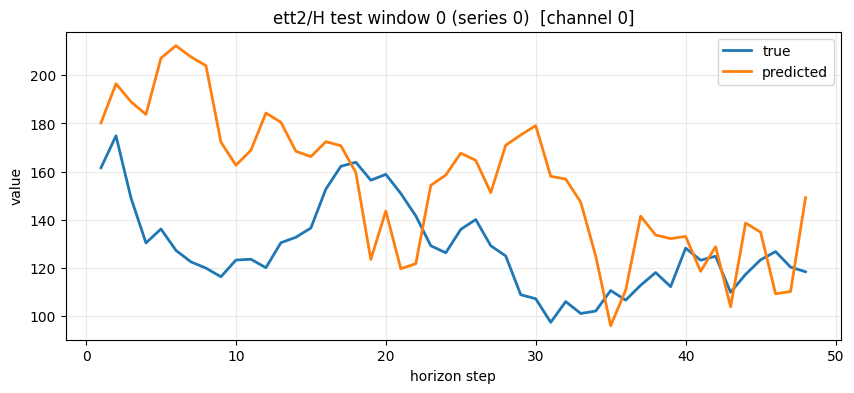

Test evaluated       : 7 (series × channel) pairs
Mean  relative L2    : 6.417782
Median relative L2   : 0.097916


In [11]:
# ── Long-term test evaluation (test window 0) ─────────────────────────
print("Long-term test evaluation …")
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_series_total = len(dataset.hf_dataset)

all_test_errors = []
plotted = False

for eval_idx in _evaluation_series_indices(n_series_total):
    val_arr = _series_from_entry_mv(_get_validation_entry(eval_idx))

    if val_arr.shape[0] < CONTEXT_LENGTH:
        continue

    try:
        test_ctx_entry, test_lbl_entry = _get_test_pair(eval_idx, 0)
    except IndexError as e:
        print(f"  skip series {eval_idx}: {e}")
        continue

    test_ctx_mv = _series_from_entry_mv(test_ctx_entry)   # (T_ctx, p)
    test_lbl_mv = _series_from_entry_mv(test_lbl_entry)   # (H_lbl, p)

    p = test_ctx_mv.shape[1]
    if test_ctx_mv.shape[0] < CONTEXT_LENGTH or test_lbl_mv.shape[0] < horizon_length:
        continue

    # Per-channel normalisation using validation stats
    query_norm = np.empty((p, CONTEXT_LENGTH), dtype=float)
    locs, scales = [], []
    for ch in range(p):
        ch_val = val_arr[:, ch]
        if NORMALIZATION == "robust_series":
            loc = float(np.nanmedian(ch_val))
            q75 = float(np.nanpercentile(ch_val, 75))
            q25 = float(np.nanpercentile(ch_val, 25))
            _iqr_s = (q75 - q25) / 1.349
            scale = max(
                _iqr_s if np.isfinite(_iqr_s) else 0.0,
                float(np.nanstd(ch_val)) if np.isfinite(float(np.nanstd(ch_val))) else 0.0,
                1e-6,
            )
        else:
            loc, scale = 0.0, 1.0
        raw_q = test_ctx_mv[-CONTEXT_LENGTH:, ch]
        query_norm[ch] = (raw_q - loc) / scale
        locs.append(loc); scales.append(scale)

    pred_norm = mv_forecaster_val.predict(query_norm)   # (p, H)

    for ch in range(p):
        pred_ch = _denorm(pred_norm[ch], locs[ch], scales[ch])
        true_ch = test_lbl_mv[:horizon_length, ch]
        err = relative_l2_error(true_ch, pred_ch)
        all_test_errors.append(err)

    if (not EVALUATE_ALL_SERIES and eval_idx == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and not plotted
    ):
        ch_plot = min(CHANNEL_INDEX, p - 1)
        _plot_channel_forecast(
            test_lbl_mv[:horizon_length, ch_plot],
            _denorm(pred_norm[ch_plot], locs[ch_plot], scales[ch_plot]),
            channel=ch_plot,
            title=f"{DATASET_NAME} test window 0 (series {eval_idx})",
        )
        plotted = True

if all_test_errors:
    arr = np.asarray(all_test_errors, dtype=float)
    print(f"Test evaluated       : {len(all_test_errors)} (series × channel) pairs")
    print(f"Mean  relative L2    : {float(np.nanmean(arr)):.6f}")
    print(f"Median relative L2   : {float(np.nanmedian(arr)):.6f}")
else:
    print("No test forecasts could be evaluated.")

## Posterior Uncertainty: selected series + channel

Posterior uncertainty: series 0, channel 0 …
  posterior std (denormalised): 0.0000


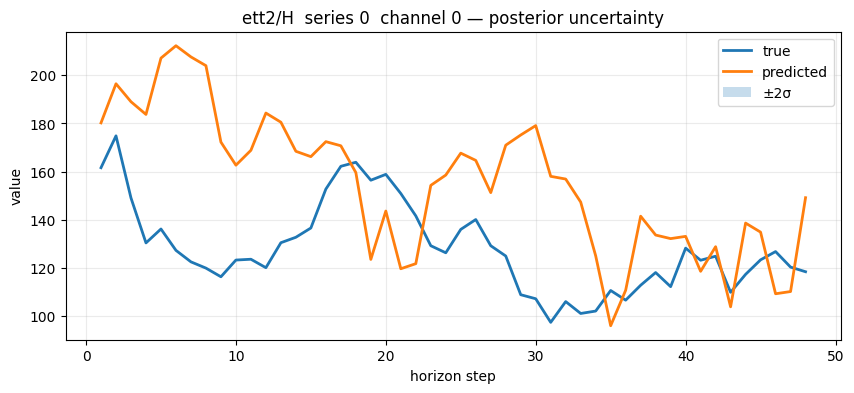

In [12]:
# ── Posterior uncertainty for selected series + channel ───────────────
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
print(f"Posterior uncertainty: series {SERIES_INDEX}, channel {CHANNEL_INDEX} …")

val_arr = _series_from_entry_mv(_get_validation_entry(SERIES_INDEX))
p = val_arr.shape[1]
ch = min(CHANNEL_INDEX, p - 1)

try:
    test_ctx_entry, test_lbl_entry = _get_test_pair(SERIES_INDEX, 0)
except IndexError as e:
    print(f"Cannot compute uncertainty: {e}")
else:
    test_ctx_mv = _series_from_entry_mv(test_ctx_entry)
    test_lbl_mv = _series_from_entry_mv(test_lbl_entry)

    # Per-channel normalisation using validation stats
    query_norm = np.empty((p, CONTEXT_LENGTH), dtype=float)
    locs, scales = [], []
    for c in range(p):
        ch_val = val_arr[:, c]
        if NORMALIZATION == "robust_series":
            loc = float(np.nanmedian(ch_val))
            q75 = float(np.nanpercentile(ch_val, 75))
            q25 = float(np.nanpercentile(ch_val, 25))
            _iqr_s = (q75 - q25) / 1.349
            scale = max(
                _iqr_s if np.isfinite(_iqr_s) else 0.0,
                float(np.nanstd(ch_val)) if np.isfinite(float(np.nanstd(ch_val))) else 0.0,
                1e-6,
            )
        else:
            loc, scale = 0.0, 1.0
        raw_q = test_ctx_mv[-CONTEXT_LENGTH:, c]
        query_norm[c] = (raw_q - loc) / scale
        locs.append(loc); scales.append(scale)

    # means: (p, H), variances: (p,)
    means_norm, variances = mv_forecaster_val.predict_with_uncertainty(query_norm)
    pred_ch = _denorm(means_norm[ch], locs[ch], scales[ch])
    std_denorm = float(np.sqrt(max(variances[ch], 0.0))) * scales[ch]
    true_ch = test_lbl_mv[:horizon_length, ch]

    print(f"  posterior std (denormalised): {std_denorm:.4f}")

    t = np.arange(1, horizon_length + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(t, true_ch, label="true", linewidth=2)
    plt.plot(t, pred_ch, label="predicted", linewidth=2)
    plt.fill_between(
        t,
        pred_ch - 2 * std_denorm,
        pred_ch + 2 * std_denorm,
        alpha=0.25,
        label="±2σ",
    )
    plt.title(f"{DATASET_NAME}  series {SERIES_INDEX}  channel {ch} — posterior uncertainty")
    plt.xlabel("horizon step")
    plt.ylabel("value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

In [13]:
# ── Export model state for cross-dataset nested kriging layer ────────────────
from pathlib import Path
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), ".."))

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

safe_name = DATASET_NAME.replace("/", "__")
save_path = models_dir / f"{safe_name}.npz"
mv_forecaster.save_state(save_path, dataset_name=DATASET_NAME)
total_blocks = sum(
    len(fc._fitted_blocks) for fc in mv_forecaster._forecasters
    if fc._fitted_blocks is not None
)
print(f"Saved MV model state → {save_path}  "
      f"({total_blocks} blocks across {mv_forecaster.n_channels} channels)")


Saved MV model state → ../models/ett2__H.npz  (49 blocks across 7 channels)
